<a href="https://colab.research.google.com/github/LuciaLicakova/Projects/blob/main/XAI_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# TiRex-2 Explainable Time-Series Forecasting

## Project overview TODO when the majority is done

This project implements an explainable AI system for forecasting transformer oil temperature using the pretrained TiRex-2 model and the ETTh1 dataset.

The system uses the historical oil-temperature measurements to predict the next 24 hours. It also provides two complementary explanation methods:

1. **Temporal occlusion:** Measures how the forecast changes when individual 24-hour periods of the historical input are replaced with interpolated values.
2. **Local surrogate model:** Approximates the behaviour of TiRex-2 around a selected input using an interpretable linear regression model.

The intended target audience is energy-system operators who want to understand the model's temperature forecasts and identify which historical observations influence its predictions.

## Requirements
Install the required packages using:

```bash
pip install tirex-2 pandas numpy matplotlib scikit-learn scipy
```

Install PyTorch using the instructions appropriate for your operating system and hardware.

A GPU is recommended but not required.

## How to run the system TODO: fix numbering

1. Open the project notebook.
2. Install the required dependencies.
3. Run all cells from top to bottom. The notebook automatically downloads the ETTh1 dataset and loads the pretrained TiRex-2 model.
5. Select a historical forecasting window by changing `TARGET_START`.
6. Alternatively, provide exactly 168 hourly oil-temperature measurements through `CUSTOM_CONTEXT`.
7. Run the forecasting cell to obtain the 24-hour forecast.
8. Examine the temporal occlusion and local surrogate explanations.
9. Compare the two explanation methods and inspect the surrogate fidelity.

## Questions
Which historical 24-hour segments influence the predicted temperature level over the next 24 hours, and how does this differ across forecast quantiles?

Which historical segments influence the prediction for each of the next 24 hours, again across multiple quantiles?

## Interpreting the results
TiRex-2 returns 9 values for each of the 24 forecast hours. At one forecast hour, e.g. q10 is the 10th percentile: 10% of the predicted distribution lies at or below this value. Each quantile describes a different position in the model’s predictive distribution, for each of the 24 future hours. We explain each quantile separately, and do not average them together. TiRex-2 receives only the 168-hour context. The preceding 24 hours are not passed to the model as additional context. They are used exclusively by the explanation method to construct replacement inputs. For an existing ETTh1 forecast origin, we can retrieve those observations from the dataset. For a custom input, the user would have to supply them separately if we want to retain the same preceding-day replacement strategy.

The forecast visualisation displays the historical observations, the predicted median temperature trajectory and the 10th–90th percentile forecast interval.

Temporal occlusion shows how replacing individual historical periods changes the predicted average temperature.

The local surrogate model assigns coefficients to the seven historical periods. These coefficients describe how retaining each period influences the surrogate's approximation of the forecast.

## Limitations

The system uses only historical oil-temperature measurements and does not incorporate the six load-related variables available in ETTh1.

The dataset is a historical benchmark rather than a live transformer monitoring system. The predictions should not be treated as fault diagnoses, safety assessments or operational alarms.

The explanations depend on the chosen perturbation baseline and the quality of the local surrogate approximation.

The system is intended for educational and exploratory purposes.

In [23]:
! pip install tirex-2 pandas numpy matplotlib scikit-learn scipy

- Context (input length): 168 hours (7 days).
- Forecast horizon: 24 hours (1 day).
- Evaluation period: final 20% of the dataset, 3,484 observations.
- Target: OT (oil temperature).
- No model training: TiRex-2 is pretrained.
The first evaluation forecast will use observations immediately before the test period, so there is no leakage from future observations.

In [24]:
import os
os.environ["TORCH_COMPILE_DISABLE"] = "1"
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from itertools import product
from tirex2 import TimeseriesType, load_model
from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score
from sklearn.model_selection import KFold
from scipy.stats import spearmanr

device = "cpu"
model = load_model("NX-AI/TiRex-2", device=device)
print("Model loaded:", device)

url = "https://raw.githubusercontent.com/zhouhaoyi/ETDataset/main/ETT-small/ETTh1.csv"
df = pd.read_csv(url)
df["date"] = pd.to_datetime(df["date"])
df = df.sort_values("date").reset_index(drop=True)

assert "OT" in df.columns
assert not df["OT"].isna().any()
assert not df["date"].duplicated().any()
assert (df["date"].diff().dropna() == pd.Timedelta(hours=1)).all()

print("Dataset shape:", df.shape)
print("Date range:", df["date"].min(), "to", df["date"].max())
print("OT range:", df["OT"].min(), "to", df["OT"].max())

CONTEXT_LENGTH = 168
PREDICTION_LENGTH = 24
SEGMENT_LENGTH = 24
N_SEGMENTS = CONTEXT_LENGTH // SEGMENT_LENGTH
segment_labels = [f"Hours {i*SEGMENT_LENGTH+1}–{(i+1)*SEGMENT_LENGTH}" for i in range(N_SEGMENTS)]

TEST_START = int(len(df) * 0.8)
print("Evaluation starts:", df.loc[TEST_START, "date"])
print("Evaluation observations:", len(df) - TEST_START)


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Model loaded: cpu
Dataset shape: (17420, 8)
Date range: 2016-07-01 00:00:00 to 2018-06-26 19:00:00
OT range: -4.079999923706056 to 46.00699996948242
Evaluation starts: 2018-02-01 16:00:00
Evaluation observations: 3484


The output shape (1, 9, 24) confirms one input series, one target variable, nine forecast quantiles and 24 hourly predictions

We evaluate the model on the held-out test period using non-overlapping 24-hour forecast windows.
We compare:
- TiRex-2: pretrained model, using the median forecast.
- Persistence: repeats the last observed temperature for all 24 hours.
- Seasonal naïve: repeats the last 24 observed hourly temperatures.

TiRex-2 performs better than both baselines on the held-out test period:
- Its MAE is 1.2237, compared with 1.6697 for persistence and 1.7144 for seasonal naive.
- Its RMSE is 1.7616, compared with 2.2371 and 2.2374, respectively.

In [38]:
from tqdm.auto import tqdm
QUANTILE_LEVELS = np.arange(0.1, 1.0, 0.1)
QUANTILE_LABELS = [f"q{int(q*100)}" for q in QUANTILE_LEVELS]

def predict_forecast(values):
    x = torch.tensor(values, dtype=torch.float32).unsqueeze(0)
    ts = TimeseriesType(target=x, past_covariates=None, future_covariates=None)
    pred = model.forecast([ts], prediction_length=PREDICTION_LENGTH, output_type="numpy")[0]
    assert pred.shape == (1, len(QUANTILE_LEVELS), PREDICTION_LENGTH), pred.shape
    return pred[0].copy()

def explain_context(context, replacement):
    context = np.asarray(context, dtype=float)
    replacement = np.asarray(replacement, dtype=float)
    assert context.shape == (CONTEXT_LENGTH,)
    assert replacement.shape == (CONTEXT_LENGTH,)
    assert np.isfinite(context).all() and np.isfinite(replacement).all()
    original = predict_forecast(context)

    # Temporal occlusion: replace one segment at a time.
    occlusion = []
    for i in tqdm(range(N_SEGMENTS),desc="Temporal occlusion"):
        start, end = i*SEGMENT_LENGTH, (i+1)*SEGMENT_LENGTH
        perturbed = context.copy()
        perturbed[start:end] = replacement[start:end]
        occlusion.append(predict_forecast(perturbed) - original)
    occlusion = np.stack(occlusion)  # (7, 9, 24)

    # Local surrogate: evaluate all 2^7 combinations.
    masks = np.array(list(product([0, 1], repeat=N_SEGMENTS)), dtype=float)
    predictions = []
    for mask in tqdm(masks,desc="Surrogate predictions"):
        perturbed = context.copy()
        for i in range(N_SEGMENTS):
            if mask[i] == 0:
                start, end = i*SEGMENT_LENGTH, (i+1)*SEGMENT_LENGTH
                perturbed[start:end] = replacement[start:end]
        predictions.append(predict_forecast(perturbed))
    predictions = np.stack(predictions)  # (128, 9, 24)
    distances = np.sqrt(np.mean((masks-1)**2, axis=1))
    weights = np.exp(-(distances/0.75)**2)

    # Average forecast: one target per quantile.
    overall_targets = predictions.mean(axis=2)
    overall_surrogate = Ridge(alpha=1e-6).fit(masks, overall_targets, sample_weight=weights)

    # Hourly forecast: one target per quantile and forecast hour.
    hourly_targets = predictions.transpose(0, 2, 1).reshape(len(masks), -1)
    hourly_surrogate = Ridge(alpha=1e-6).fit(masks, hourly_targets, sample_weight=weights)
    hourly_coefficients = hourly_surrogate.coef_.reshape(PREDICTION_LENGTH, len(QUANTILE_LEVELS), N_SEGMENTS)

    # Five-fold cross-validated weighted R² on the generated perturbations.
    cv = KFold(n_splits=5, shuffle=True, random_state=42)
    overall_oof = np.empty_like(overall_targets)
    hourly_oof = np.empty_like(hourly_targets)

    for train_idx,test_idx in tqdm(cv.split(masks),total=cv.get_n_splits(),desc="Cross-validation"):
        overall_fold = Ridge(alpha=1e-6).fit(masks[train_idx], overall_targets[train_idx], sample_weight=weights[train_idx])
        overall_oof[test_idx] = overall_fold.predict(masks[test_idx])
        hourly_fold = Ridge(alpha=1e-6).fit(masks[train_idx], hourly_targets[train_idx], sample_weight=weights[train_idx])
        hourly_oof[test_idx] = hourly_fold.predict(masks[test_idx])

    overall_r2 = r2_score(overall_targets, overall_oof, sample_weight=weights, multioutput="raw_values")
    hourly_r2 = r2_score(hourly_targets, hourly_oof, sample_weight=weights, multioutput="raw_values")
    hourly_r2 = hourly_r2.reshape(PREDICTION_LENGTH, len(QUANTILE_LEVELS))
    overall_coefficients = pd.DataFrame(overall_surrogate.coef_.T, index=segment_labels, columns=QUANTILE_LABELS)

    return {
        "forecast": original,
        "occlusion_changes": occlusion,
        "masks": masks,
        "predictions": predictions,
        "weights": weights,
        "overall_targets": overall_targets,
        "overall_surrogate": overall_surrogate,
        "hourly_surrogate": hourly_surrogate,
        "overall_coefficients": overall_coefficients,
        "hourly_coefficients": hourly_coefficients,
        "overall_r2": overall_r2,
        "hourly_r2": hourly_r2
    }

def get_input(origin):
    assert CONTEXT_LENGTH+SEGMENT_LENGTH <= origin <= len(df)-PREDICTION_LENGTH
    context = df["OT"].iloc[origin-CONTEXT_LENGTH:origin].to_numpy(dtype=float)
    replacement = df["OT"].iloc[origin-CONTEXT_LENGTH-SEGMENT_LENGTH:origin-SEGMENT_LENGTH].to_numpy(dtype=float)
    return context, replacement

# Probabilistic forecast evaluation on the held-out test period
evaluation_origins = np.arange(TEST_START, len(df) - PREDICTION_LENGTH + 1, PREDICTION_LENGTH)

all_forecasts = []
all_actuals = []

for origin in tqdm(evaluation_origins,desc="Forecast evaluation"):
    context = df["OT"].iloc[origin-CONTEXT_LENGTH:origin].to_numpy(dtype=float)
    actual = df["OT"].iloc[origin:origin+PREDICTION_LENGTH].to_numpy(dtype=float)

    all_forecasts.append(predict_forecast(context))
    all_actuals.append(actual)

all_forecasts = np.stack(all_forecasts)  # (145, 9, 24)
all_actuals = np.stack(all_actuals)      # (145, 24)

assert all_forecasts.shape == (len(evaluation_origins), 9, PREDICTION_LENGTH)
assert all_actuals.shape == (len(evaluation_origins), PREDICTION_LENGTH)

# Median forecast metrics
median_forecast = all_forecasts[:, 4, :]
mae = np.abs(all_actuals - median_forecast).mean()
rmse = np.sqrt(((all_actuals - median_forecast) ** 2).mean())

# Pinball loss for all nine quantiles
errors = all_actuals[:, None, :] - all_forecasts
quantiles = QUANTILE_LEVELS[None, :, None]
pinball_losses = np.maximum(quantiles * errors, (quantiles - 1) * errors).mean(axis=(0, 2))

# Empirical coverage and average width of the 10th–90th percentile interval
lower = all_forecasts[:, 0, :]
upper = all_forecasts[:, 8, :]
coverage = ((all_actuals >= lower) & (all_actuals <= upper)).mean()
interval_width = (upper - lower).mean()

print("Number of forecast origins:", len(evaluation_origins))
print("Number of evaluated observations:", all_actuals.size)
print(f"Median MAE: {mae:.4f}")
print(f"Median RMSE: {rmse:.4f}")
print(f"10th–90th interval coverage: {coverage:.4f} ({coverage*100:.2f}%)")
print(f"10th–90th interval average width: {interval_width:.4f}")

probabilistic_results = pd.DataFrame({"Quantile": QUANTILE_LABELS, "Pinball loss": pinball_losses})
display(probabilistic_results.round(4))

Forecast evaluation:   0%|          | 0/145 [00:00<?, ?it/s]

Number of forecast origins: 145
Number of evaluated observations: 3480
Median MAE: 1.2237
Median RMSE: 1.7616
10th–90th interval coverage: 0.8129 (81.29%)
10th–90th interval average width: 3.8183


,Quantile,Pinball loss
0,q10,0.3595
1,q20,0.4931
2,q30,0.5707
3,q40,0.6090
4,q50,0.6118
5,q60,0.5811
6,q70,0.5178
7,q80,0.4171
8,q90,0.2686


Mean_change  Mean_absolute_change  Std_change  \
Segment       Quantile                                                  
Hours 121–144 q10           -0.1174                0.3084      0.4213   
              q20           -0.1355                0.3013      0.4419   
              q30           -0.1256                0.2898      0.4270   
              q40           -0.1197                0.2845      0.4252   
              q50           -0.1157                0.2858      0.4255   
...                             ...                   ...         ...   
Hours 97–120  q50           -0.0349                0.2188      0.2268   
              q60           -0.0242                0.2208      0.2310   
              q70           -0.0143                0.2269      0.2460   
              q80           -0.0037                0.2422      0.2748   
              q90            0.0093                0.2782      0.3279   

                        Mean_hourly_variation  
Segment       Quantile                         
Hours 121–144 q10                      0.2240  
              q20                      0.2202  
              q30                      0.2053  
              q40                      0.1888  
              q50                      0.1738  
...                                       ...  
Hours 97–120  q50                      0.1598  
              q60                      0.1605  
              q70                      0.1623  
              q80                      0.1672  
              q90                      0.1845  

[63 rows x 4 columns]

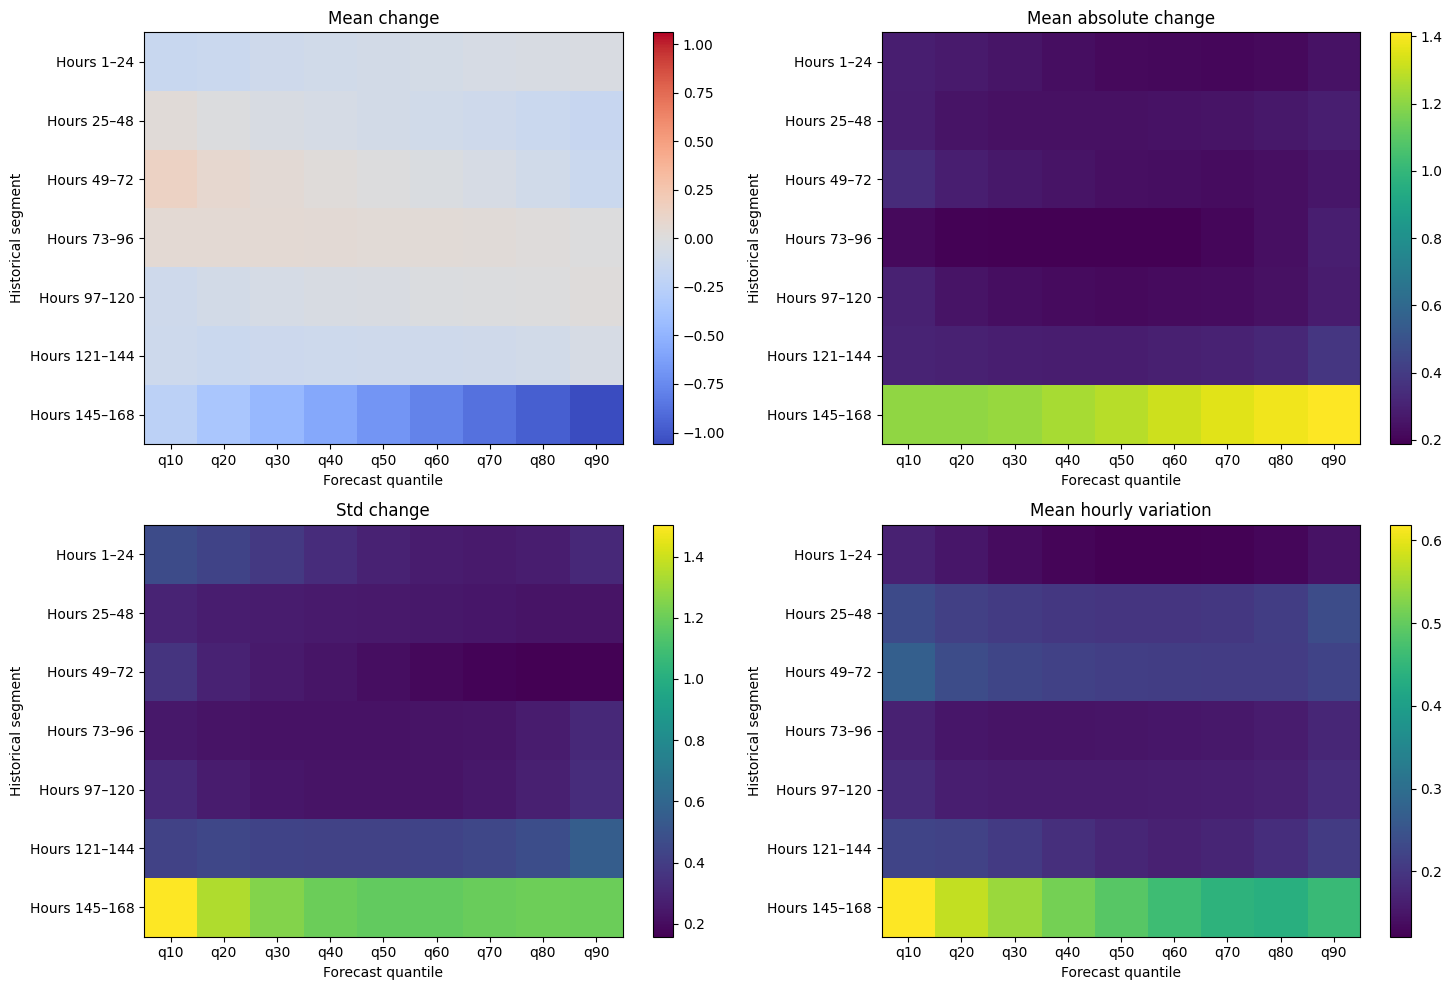

In [26]:
origins = np.linspace(TEST_START, len(df)-PREDICTION_LENGTH, 20, dtype=int)
robustness_results = []

for origin in origins:
    context_values, replacement_values = get_input(origin)
    baseline = predict_forecast(context_values)

    for i in range(N_SEGMENTS):
        start, end = i*SEGMENT_LENGTH, (i+1)*SEGMENT_LENGTH
        perturbed = context_values.copy()
        perturbed[start:end] = replacement_values[start:end]

        changed = predict_forecast(perturbed)
        delta = changed - baseline  # (9, 24)

        for q_idx, q_label in enumerate(QUANTILE_LABELS):
            robustness_results.append({
                "Origin": df["date"].iloc[origin],
                "Segment": segment_labels[i],
                "Quantile": q_label,
                "Mean_change": delta[q_idx].mean(),
                "Mean_absolute_change": np.abs(delta[q_idx]).mean(),
                "Std_hourly_change": delta[q_idx].std()
            })

robustness_df = pd.DataFrame(robustness_results)

robustness_summary = robustness_df.groupby(["Segment", "Quantile"]).agg(
    Mean_change=("Mean_change", "mean"),
    Mean_absolute_change=("Mean_absolute_change", "mean"),
    Std_change=("Mean_change", "std"),
    Mean_hourly_variation=("Std_hourly_change", "mean")
).round(4)

display(robustness_summary)

metrics = ["Mean_change", "Mean_absolute_change", "Std_change", "Mean_hourly_variation"]
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

for ax, metric in zip(axes.flat, metrics):
    table = robustness_summary[metric].unstack("Quantile")
    table = table.reindex(index=segment_labels, columns=QUANTILE_LABELS)

    if metric == "Mean_change":
        limit = np.abs(table.to_numpy()).max()
        im = ax.imshow(table, aspect="auto", cmap="coolwarm", vmin=-limit, vmax=limit)
    else:
        im = ax.imshow(table, aspect="auto", cmap="viridis")

    ax.set_title(metric.replace("_", " "))
    ax.set_xticks(range(len(QUANTILE_LABELS)), QUANTILE_LABELS)
    ax.set_yticks(range(len(segment_labels)), segment_labels)
    ax.set_xlabel("Forecast quantile")
    ax.set_ylabel("Historical segment")
    fig.colorbar(im, ax=ax)

plt.tight_layout()
plt.show()

Both explanation methods examine all nine forecast quantiles. They investigate which historical segments influence the average predicted temperature over the 24-hour horizon and how these influences vary across individual forecast hours.
- Temporal occlusion measures how much the prediction changes when one 24-hour segment is replaced.
- The local surrogate generates combinations of changed segments and learns a simple model that approximates TiRex-2's behaviour around one particular input.

**Perturbation strategy**: our input consists of 168 hourly observations, divided into seven consecutive 24-hour segments. For each segment, we replace its values with the corresponding observations from the preceding day.

**Temporal occlusion**: For each of the seven segments, we replace only that segment and leave the remaining six unchanged. We then compare the perturbed forecast with the original forecast.
| Input segment | Replacement |
| --- | --- |
| Hours 1–24 | 24 hours immediately before the context |
| Hours 25–48 | Original context hours 1–24 |
| Hours 49–72 | Original context hours 25–48 |
| Hours 73–96 | Original context hours 49–72 |
| Hours 97–120 | Original context hours 73–96 |
| Hours 121–144 | Original context hours 97–120 |
| Hours 145–168 | Original context hours 121–144 |


The primary explanation value is:
$$
\Delta_i =
\frac{1}{24}\sum_{h=1}^{24}
\widehat{y}^{\,\text{occluded}}_{i,h}
-
\frac{1}{24}\sum_{h=1}^{24}
\widehat{y}^{\,\text{original}}_h.
$$
A negative value means that the replacement lowered the mean forecast. A positive value means that it raised it.


**Local surrogate**: Which parts of this historical temperature sequence are most influential in TiRex-2's forecast for this particular point in time?

To investigate this, we create 128 modified versions of the original history. Each version is represented by a binary mask:
- 1: retain the original 24-hour segment.
- 0: replace that segment with the corresponding observations from the preceding day.
The we ask TiRex-2 to forecast using each modified history.

Consider two modified histories:
- History A replaces just one of the seven segments.
- History B replaces all seven segments.
History A is much closer to the actual input that we want to explain. Hence we use perturbation weighting.

In exact terms: We have 7 segments, each represented by a binary variable:
$$
z_i =
\begin{cases}
1 & \text{original segment retained},\\
0 & \text{segment replaced by preceding-day observations}.
\end{cases}
$$
There are $2^7=128$ possible binary combinations. For each combination, TiRex-2 produces a mean forecast. We then fit a weighted linear regression:
$$
g(z)=\beta_0+\sum_{i=1}^{7}\beta_i z_i.
$$
We calculate the distance of each binary mask $z$ from the original mask (all ones):
$$
d(z,\mathbf{1})=\sqrt{\frac{1}{7}\sum_{i=1}^{7}(z_i-1)^2}.
$$

Then we assign each mask a weight:
$$
w(z)=\exp\left(-\left(\frac{d(z,\mathbf{1})}{0.75}\right)^2\right).
$$
The original context corresponds to $z=\mathbf{1}$: none of the segments is replaced. Its distance is zero and its weight is 1.

This is a LIME-style method because it fits a simple interpretable model around one input, using proximity weights.
The coefficients describe how the surrogate's predicted mean changes when a segment is retained rather than replaced, while accounting for the other binary variables.
- A positive coefficient means retaining that segment is associated with a higher surrogate prediction.
- A negative coefficient means retaining it is associated with a lower surrogate prediction.
- A coefficient close to zero indicates a small contribution in this local linear approximation.
The weighted $R^2$ measures how accurately the surrogate reproduces TiRex-2's predictions on the generated perturbations, with greater emphasis on inputs close to the original context. A high weighted $R^2$ supports the use of the linear surrogate in this neighbourhood. A low value means that a linear explanation is insufficient to represent the model's local behaviour.

Forecast origin: 2018-02-01 16:00:00
Forecast shape: (9, 24)


,q10,q20,q30,q40,q50,q60,q70,q80,q90
Hours 1–24,-0.0411,-0.1924,-0.2767,-0.3334,-0.3723,-0.3946,-0.4070,-0.4353,-0.5099
Hours 25–48,0.0358,-0.0955,-0.1673,-0.2197,-0.2681,-0.3166,-0.3629,-0.4014,-0.4413
Hours 49–72,-0.2809,-0.2611,-0.2617,-0.2704,-0.2751,-0.2653,-0.2397,-0.2015,-0.1478
Hours 73–96,0.0557,0.1116,0.1177,0.1050,0.0757,0.0290,-0.0355,-0.1294,-0.3012
Hours 97–120,0.1248,0.0802,0.0581,0.0429,0.0283,0.0081,-0.0200,-0.0584,-0.1153
Hours 121–144,-0.1554,-0.1566,-0.1789,-0.2218,-0.2913,-0.3949,-0.5369,-0.7251,-1.0219
Hours 145–168,-0.2971,-0.6287,-1.0259,-1.4054,-1.7876,-2.2044,-2.6287,-2.9368,-3.0044


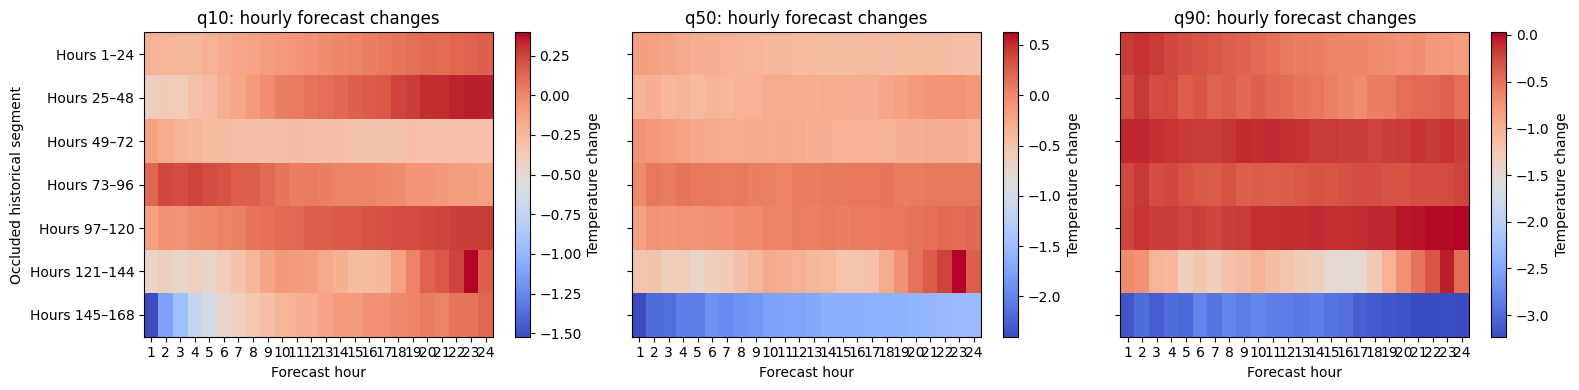

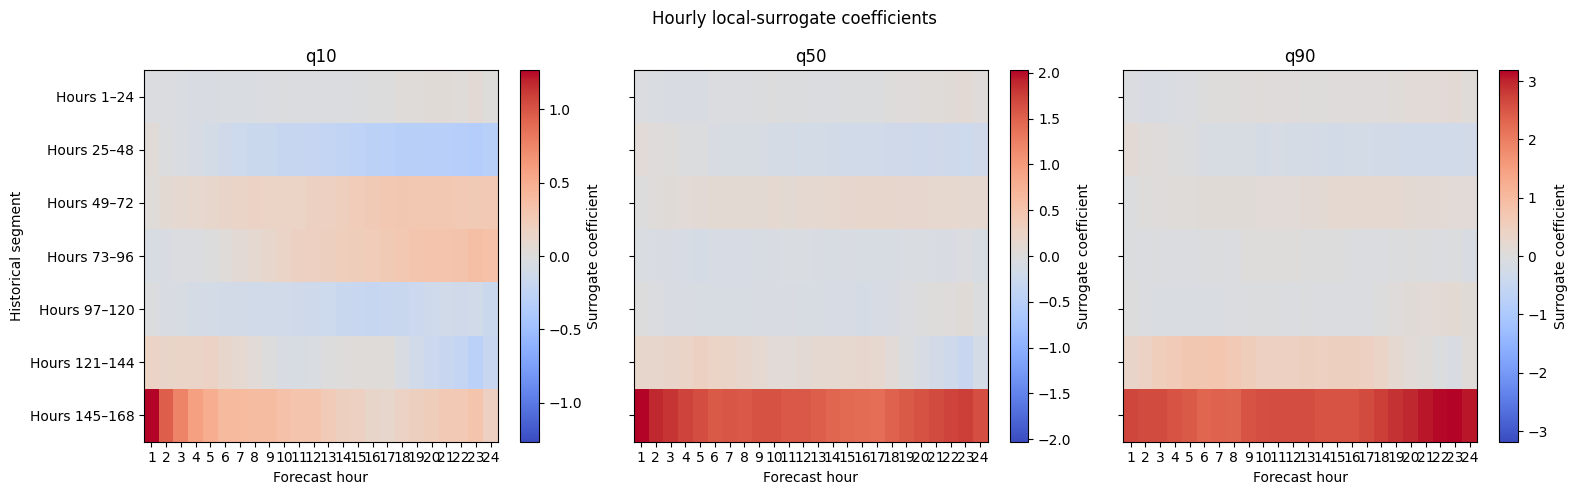

In [35]:
TARGET_START = TEST_START
context_values, replacement_values = get_input(TARGET_START)
context_dates = df["date"].iloc[TARGET_START-CONTEXT_LENGTH:TARGET_START]
future_dates = df["date"].iloc[TARGET_START:TARGET_START+PREDICTION_LENGTH]

explanation = explain_context(context_values, replacement_values)
original_forecast = explanation["forecast"]
occlusion_changes = explanation["occlusion_changes"]
masks = explanation["masks"]
predictions = explanation["predictions"]
weights = explanation["weights"]
overall_targets = explanation["overall_targets"]
overall_surrogate = explanation["overall_surrogate"]
hourly_surrogate = explanation["hourly_surrogate"]
overall_coefficients = explanation["overall_coefficients"]
hourly_coefficients = explanation["hourly_coefficients"]
overall_r2 = explanation["overall_r2"]
hourly_r2 = explanation["hourly_r2"]

print("Forecast origin:", df["date"].iloc[TARGET_START])
print("Forecast shape:", original_forecast.shape)

# Overall effect: average the change across the 24 forecast hours, separately for each quantile
overall_changes = occlusion_changes.mean(axis=2)  # (7, 9)
overall_occlusion_df = pd.DataFrame(overall_changes, index=segment_labels, columns=QUANTILE_LABELS)
display(overall_occlusion_df.round(4))

# One heatmap per representative quantile
fig, axes = plt.subplots(1, 3, figsize=(16, 4), sharey=True)
for ax, q_idx in zip(axes, [0, 4, 8]):
    im = ax.imshow(occlusion_changes[:, q_idx, :], aspect="auto", cmap="coolwarm")
    ax.set_title(f"{QUANTILE_LABELS[q_idx]}: hourly forecast changes")
    ax.set_xlabel("Forecast hour")
    ax.set_xticks(range(PREDICTION_LENGTH))
    ax.set_xticklabels(range(1, PREDICTION_LENGTH+1))
    ax.set_yticks(range(N_SEGMENTS))
    ax.set_yticklabels(segment_labels)
    fig.colorbar(im, ax=ax, label="Temperature change")

axes[0].set_ylabel("Occluded historical segment")
plt.tight_layout()
plt.show()

# Hourly local-surrogate coefficients
fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)

for ax, q_idx in zip(axes, [0, 4, 8]):
    values = hourly_coefficients[:, q_idx, :].T
    limit = np.abs(values).max()
    im = ax.imshow(values, aspect="auto", cmap="coolwarm", vmin=-limit, vmax=limit)
    ax.set_title(QUANTILE_LABELS[q_idx])
    ax.set_xlabel("Forecast hour")
    ax.set_xticks(range(PREDICTION_LENGTH), range(1, PREDICTION_LENGTH+1))
    ax.set_yticks(range(N_SEGMENTS), segment_labels)
    fig.colorbar(im, ax=ax, label="Surrogate coefficient")

axes[0].set_ylabel("Historical segment")
fig.suptitle("Hourly local-surrogate coefficients")
plt.tight_layout()
plt.show()

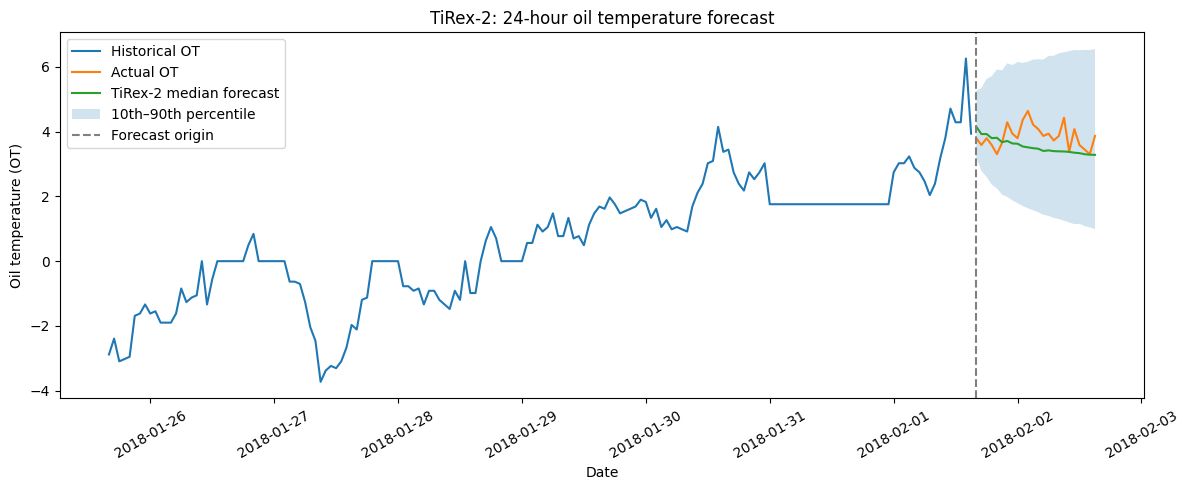

In [28]:
plt.figure(figsize=(12, 5))
plt.plot(context_dates, context_values, label="Historical OT")
plt.plot(future_dates, df["OT"].iloc[TARGET_START:TARGET_START+PREDICTION_LENGTH], label="Actual OT")
plt.plot(future_dates, original_forecast[4], label="TiRex-2 median forecast")
plt.fill_between(future_dates, original_forecast[0], original_forecast[8], alpha=0.2, label="10th–90th percentile")
plt.axvline(future_dates.iloc[0], linestyle="--", color="grey", label="Forecast origin")
plt.xlabel("Date")
plt.ylabel("Oil temperature (OT)")
plt.title("TiRex-2: 24-hour oil temperature forecast")
plt.legend()
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [29]:
# Compare temporal occlusion baselines
def interpolate_segment(context, start, end):
    result = context.copy()
    left = result[start-1] if start > 0 else result[end]
    right = result[end] if end < len(result) else result[start-1]
    result[start:end] = np.linspace(left, right, end-start+2)[1:-1]
    return result

baseline_methods = ["Previous day", "Segment mean", "Linear interpolation"]
baseline_occlusion = {}
for method in baseline_methods:
    changes = []

    for i in range(N_SEGMENTS):
        start, end = i*SEGMENT_LENGTH, (i+1)*SEGMENT_LENGTH
        perturbed = context_values.copy()
        if method == "Previous day":
            perturbed[start:end] = replacement_values[start:end]
        elif method == "Segment mean":
            perturbed[start:end] = context_values[start:end].mean()
        else:
            perturbed = interpolate_segment(context_values, start, end)
        changed_forecast = predict_forecast(perturbed)
        changes.append(changed_forecast - original_forecast)
    baseline_occlusion[method] = np.stack(changes)

# Mean forecast change for every segment and quantile
baseline_summary = []
for method, changes in baseline_occlusion.items():
    for i, segment in enumerate(segment_labels):
        for q_idx, quantile in enumerate(QUANTILE_LABELS):
            delta = changes[i, q_idx]
            baseline_summary.append({
                "Baseline": method,
                "Segment": segment,
                "Quantile": quantile,
                "Mean_change": delta.mean(),
                "Mean_absolute_change": np.abs(delta).mean()
            })

baseline_summary_df = pd.DataFrame(baseline_summary)
comparison = baseline_summary_df.pivot_table(index=["Baseline", "Segment"], columns="Quantile", values="Mean_absolute_change").reindex(columns=QUANTILE_LABELS)
display(comparison.round(3))
ranking = baseline_summary_df.groupby(["Baseline", "Segment"])["Mean_absolute_change"].mean().unstack("Baseline")
display(ranking.round(3))

Quantile                              q10    q20    q30    q40    q50    q60  \
Baseline             Segment                                                   
Linear interpolation Hours 121–144  0.221  0.186  0.187  0.208  0.243  0.284   
                     Hours 145–168  0.448  0.591  1.023  1.402  1.787  2.219   
                     Hours 1–24     0.337  0.340  0.353  0.372  0.389  0.395   
                     Hours 25–48    0.241  0.144  0.099  0.078  0.063  0.049   
                     Hours 49–72    0.118  0.090  0.094  0.110  0.108  0.080   
                     Hours 73–96    0.262  0.388  0.472  0.526  0.537  0.485   
                     Hours 97–120   0.147  0.063  0.022  0.019  0.058  0.130   
Previous day         Hours 121–144  0.250  0.294  0.337  0.380  0.432  0.497   
                     Hours 145–168  0.327  0.629  1.026  1.405  1.788  2.204   
                     Hours 1–24     0.117  0.192  0.277  0.333  0.372  0.395   
                     Hours 25–48    0.221  0.173  0.186  0.220  0.268  0.317   
                     Hours 49–72    0.281  0.261  0.262  0.270  0.275  0.265   
                     Hours 73–96    0.104  0.112  0.118  0.105  0.078  0.038   
                     Hours 97–120   0.146  0.114  0.101  0.095  0.093  0.086   
Segment mean         Hours 121–144  0.155  0.247  0.382  0.505  0.602  0.646   
                     Hours 145–168  0.347  0.289  0.220  0.336  0.689  1.096   
                     Hours 1–24     0.150  0.130  0.123  0.125  0.132  0.140   
                     Hours 25–48    0.470  0.374  0.337  0.316  0.293  0.255   
                     Hours 49–72    0.079  0.100  0.114  0.125  0.134  0.141   
                     Hours 73–96    0.131  0.273  0.365  0.425  0.451  0.432   
                     Hours 97–120   0.185  0.209  0.335  0.396  0.390  0.304   

Quantile                              q70    q80    q90  
Baseline             Segment                             
Linear interpolation Hours 121–144  0.320  0.333  0.312  
                     Hours 145–168  2.724  3.362  4.310  
                     Hours 1–24     0.386  0.356  0.299  
                     Hours 25–48    0.045  0.076  0.135  
                     Hours 49–72    0.027  0.077  0.239  
                     Hours 73–96    0.369  0.244  0.219  
                     Hours 97–120   0.234  0.372  0.583  
Previous day         Hours 121–144  0.592  0.745  1.022  
                     Hours 145–168  2.629  2.937  3.004  
                     Hours 1–24     0.407  0.435  0.510  
                     Hours 25–48    0.363  0.401  0.441  
                     Hours 49–72    0.240  0.202  0.148  
                     Hours 73–96    0.039  0.129  0.301  
                     Hours 97–120   0.080  0.087  0.119  
Segment mean         Hours 121–144  0.619  0.494  0.264  
                     Hours 145–168  1.580  2.191  3.107  
                     Hours 1–24     0.151  0.172  0.218  
                     Hours 25–48    0.205  0.157  0.109  
                     Hours 49–72    0.148  0.162  0.177  
                     Hours 73–96    0.369  0.279  0.212  
                     Hours 97–120   0.135  0.127  0.502

Baseline,Linear interpolation,Previous day,Segment mean
Segment,,,
Hours 121–144,0.255,0.505,0.435
Hours 145–168,1.985,1.772,1.095
Hours 1–24,0.359,0.338,0.149
Hours 25–48,0.103,0.288,0.279
Hours 49–72,0.105,0.245,0.131
Hours 73–96,0.389,0.114,0.326
Hours 97–120,0.181,0.102,0.287


In [30]:
from scipy.stats import spearmanr
rank_consistency = pd.DataFrame({a: {b: spearmanr(ranking[a], ranking[b]).statistic for b in ranking.columns} for a in ranking.columns})
display(rank_consistency.round(3))
quantile_rankings = baseline_summary_df.pivot_table(index=["Quantile", "Segment"], columns="Baseline", values="Mean_absolute_change")
quantile_correlations = pd.concat({q: quantile_rankings.loc[q].corr(method="spearman") for q in QUANTILE_LABELS}, names=["Quantile"])
display(quantile_correlations.round(3))

,Linear interpolation,Previous day,Segment mean
Linear interpolation,1.000,0.393,0.643
Previous day,0.393,1.000,0.429
Segment mean,0.643,0.429,1.000


Baseline                       Linear interpolation  Previous day  \
Quantile Baseline                                                   
q10      Linear interpolation                 1.000        -0.107   
         Previous day                        -0.107         1.000   
         Segment mean                         0.321         0.250   
q20      Linear interpolation                 1.000         0.286   
         Previous day                         0.286         1.000   
         Segment mean                         0.429        -0.036   
q30      Linear interpolation                 1.000         0.571   
         Previous day                         0.571         1.000   
         Segment mean                         0.143        -0.143   
q40      Linear interpolation                 1.000         0.607   
         Previous day                         0.607         1.000   
         Segment mean                         0.143        -0.071   
q50      Linear interpolation                 1.000         0.429   
         Previous day                         0.429         1.000   
         Segment mean                         0.429         0.286   
q60      Linear interpolation                 1.000         0.286   
         Previous day                         0.286         1.000   
         Segment mean                         0.536         0.321   
q70      Linear interpolation                 1.000         0.464   
         Previous day                         0.464         1.000   
         Segment mean                         0.607         0.607   
q80      Linear interpolation                 1.000         0.286   
         Previous day                         0.286         1.000   
         Segment mean                         0.357         0.750   
q90      Linear interpolation                 1.000         0.321   
         Previous day                         0.321         1.000   
         Segment mean                         0.964         0.357   

Baseline                       Segment mean  
Quantile Baseline                            
q10      Linear interpolation         0.321  
         Previous day                 0.250  
         Segment mean                 1.000  
q20      Linear interpolation         0.429  
         Previous day                -0.036  
         Segment mean                 1.000  
q30      Linear interpolation         0.143  
         Previous day                -0.143  
         Segment mean                 1.000  
q40      Linear interpolation         0.143  
         Previous day                -0.071  
         Segment mean                 1.000  
q50      Linear interpolation         0.429  
         Previous day                 0.286  
         Segment mean                 1.000  
q60      Linear interpolation         0.536  
         Previous day                 0.321  
         Segment mean                 1.000  
q70      Linear interpolation         0.607  
         Previous day                 0.607  
         Segment mean                 1.000  
q80      Linear interpolation         0.357  
         Previous day                 0.750  
         Segment mean                 1.000  
q90      Linear interpolation         0.964  
         Previous day                 0.357  
         Segment mean                 1.000

### Temporal occlusion robustness

We evaluated the sensitivity of temporal occlusion explanations to the choice of perturbation baseline. For each of the seven 24-hour input segments, we compared three replacement strategies: observations from the preceding day, the segment's mean temperature and linear interpolation between its neighbouring observations. All experiments used the same forecast origin and measured changes across all nine forecast quantiles and 24 forecast hours.

The most recent segment (Hours 145–168)produced the largest average absolute forecast change under all three baselines. However, for example, Hours 73–96 had greater influence under linear interpolation and segment-mean replacement than under preceding-day replacement.

Spearman rank correlations confirmed this sensitivity. When averaged across quantiles, correlations between baseline-specific segment rankings ranged from 0.393 to 0.643. Quantile-specific correlations varied even more, ranging from −0.143 to 0.964. Thus, agreement between baselines also depends on the forecast quantile being explained.

Overall, the influence of the most recent 24 hours was consistent across the tested baselines, but the importance of earlier segments was more sensitive to the replacement strategy. Hence we need to interpret temporal occlusion results in relation to the chosen perturbation baseline.

In [31]:
print("Overall forecast: cross-validated weighted R² by quantile")
display(pd.Series(overall_r2, index=QUANTILE_LABELS).round(4).to_frame("Weighted R²"))

print("Overall forecast: surrogate coefficients")
display(overall_coefficients.round(4))

print("Hourly forecast: cross-validated weighted R²")
display(pd.DataFrame(
    hourly_r2,
    index=[f"Hour {h}" for h in range(1, PREDICTION_LENGTH+1)],
    columns=QUANTILE_LABELS
).round(4))

print("Original TiRex-2 average forecast by quantile")
display(pd.Series(overall_targets[np.all(masks == 1, axis=1)][0], index=QUANTILE_LABELS).round(4))
print("Overall surrogate prediction at the original input")
display(pd.Series(overall_surrogate.predict(np.ones((1, N_SEGMENTS)))[0], index=QUANTILE_LABELS).round(4))

print("Original TiRex-2 hourly forecast")
display(pd.DataFrame(
    original_forecast.T,
    columns=QUANTILE_LABELS,
    index=[f"Hour {h}" for h in range(1, PREDICTION_LENGTH+1)]
).round(4))

Overall forecast: cross-validated weighted R² by quantile


,Weighted R²
q10,0.5264
q20,0.8002
q30,0.9164
q40,0.9525
q50,0.9681
q60,0.9766
q70,0.9797
q80,0.9753
q90,0.9541


Overall forecast: surrogate coefficients


,q10,q20,q30,q40,q50,q60,q70,q80,q90
Hours 1–24,-0.0098,-0.0012,-0.0046,-0.0106,-0.0158,-0.0198,-0.0215,-0.0113,0.0217
Hours 25–48,-0.2057,-0.1508,-0.1345,-0.1275,-0.1221,-0.1179,-0.1212,-0.1413,-0.1533
Hours 49–72,0.1863,0.1349,0.1250,0.1227,0.1210,0.1189,0.1192,0.1246,0.1142
Hours 73–96,0.1638,0.0245,-0.0322,-0.0599,-0.0764,-0.0861,-0.0878,-0.0774,-0.0342
Hours 97–120,-0.1200,-0.0669,-0.0528,-0.0540,-0.0599,-0.0666,-0.0697,-0.0553,-0.0162
Hours 121–144,-0.0125,0.0279,0.0428,0.0560,0.0806,0.1250,0.1926,0.2839,0.4045
Hours 145–168,0.3768,0.6600,0.9884,1.3075,1.6224,1.9495,2.2718,2.5162,2.6699


Hourly forecast: cross-validated weighted R²


,q10,q20,q30,q40,q50,q60,q70,q80,q90
Hour 1,0.9398,0.9604,0.9683,0.9726,0.9753,0.9769,0.9774,0.9763,0.9711
Hour 2,0.8853,0.9371,0.9557,0.9654,0.9715,0.9755,0.9776,0.9773,0.9716
Hour 3,0.8004,0.8991,0.9319,0.9479,0.9572,0.9633,0.9670,0.9675,0.9609
Hour 4,0.7013,0.8639,0.9150,0.9380,0.9511,0.9591,0.9633,0.9629,0.9526
Hour 5,0.6083,0.8256,0.8927,0.9214,0.9373,0.9469,0.9519,0.9504,0.9348
Hour 6,0.5200,0.7986,0.8868,0.9211,0.9389,0.9491,0.9531,0.9493,0.9276
Hour 7,0.5260,0.8110,0.9001,0.9313,0.9461,0.9538,0.9556,0.9497,0.9258
Hour 8,0.5103,0.8090,0.9056,0.9372,0.9519,0.9596,0.9615,0.9554,0.9297
Hour 9,0.5120,0.8197,0.9220,0.9529,0.9665,0.9736,0.9752,0.9693,0.9421
Hour 10,0.4782,0.7906,0.9149,0.9523,0.9685,0.9769,0.9791,0.9727,0.9422


... (2 outputs left out)

Overall surrogate prediction at the original input


,0
q10,1.6785
q20,2.2541
q30,2.6615
q40,3.0136
q50,3.3653
q60,3.7572
q70,4.2184
q80,4.8131
q90,5.7224


Original TiRex-2 hourly forecast


,q10,q20,q30,q40,q50,q60,q70,q80,q90
Hour 1,3.2039,3.5524,3.7843,3.9761,4.1560,4.3427,4.5548,4.8286,5.2705
Hour 2,2.7892,3.1890,3.4675,3.7010,3.9272,4.1643,4.4365,4.7883,5.3469
Hour 3,2.6003,3.0578,3.3827,3.6592,3.9273,4.2099,4.5387,4.9653,5.6305
Hour 4,2.3672,2.8477,3.1954,3.5012,3.8004,4.1201,4.4911,4.9748,5.7165
Hour 5,2.2449,2.7653,3.1425,3.4780,3.8115,4.1657,4.5748,5.1053,5.9197
Hour 6,2.0571,2.5885,2.9784,3.3285,3.6771,4.0517,4.4876,5.0498,5.8970
Hour 7,1.9848,2.5490,2.9641,3.3373,3.7134,4.1219,4.5971,5.2027,6.1107
Hour 8,1.8768,2.4582,2.8802,3.2562,3.6369,4.0516,4.5341,5.1446,6.0597
Hour 9,1.7903,2.3896,2.8288,3.2255,3.6281,4.0659,4.5713,5.2071,6.1539
Hour 10,1.6998,2.3062,2.7464,3.1409,3.5437,3.9868,4.5031,5.1538,6.1255


In [32]:
baseline_surrogates = {}
cv = KFold(n_splits=5, shuffle=True, random_state=42)

for method in ["Previous day", "Segment mean", "Linear interpolation"]:
    baseline_predictions = []
    for mask in masks:
        perturbed = context_values.copy()
        for i in range(N_SEGMENTS):
            if mask[i] == 0:
                start, end = i*SEGMENT_LENGTH, (i+1)*SEGMENT_LENGTH
                if method == "Previous day": perturbed[start:end] = replacement_values[start:end]
                elif method == "Segment mean": perturbed[start:end] = context_values[start:end].mean()
                else: perturbed[start:end] = interpolate_segment(context_values, start, end)[start:end]
        baseline_predictions.append(predict_forecast(perturbed))
    targets = np.stack(baseline_predictions).mean(axis=2)
    surrogate = Ridge(alpha=1e-6).fit(masks, targets, sample_weight=weights)
    oof = np.empty_like(targets)
    for train, test in cv.split(masks):
        fold = Ridge(alpha=1e-6).fit(masks[train], targets[train], sample_weight=weights[train])
        oof[test] = fold.predict(masks[test])
    baseline_surrogates[method] = {"coefficients": pd.DataFrame(surrogate.coef_.T, index=segment_labels, columns=QUANTILE_LABELS), "r2": r2_score(targets, oof, sample_weight=weights, multioutput="raw_values")}

for method, result in baseline_surrogates.items():
    print(f"\n{method} — coefficients")
    display(result["overall_coefficients"].round(3))

print("\nCross-validated weighted R²")
display(pd.DataFrame({method: result["r2"] for method, result in baseline_surrogates.items()}, index=QUANTILE_LABELS).round(3))


Previous day — coefficients


,q10,q20,q30,q40,q50,q60,q70,q80,q90
Hours 1–24,-0.010,-0.001,-0.005,-0.011,-0.016,-0.020,-0.022,-0.011,0.022
Hours 25–48,-0.206,-0.151,-0.135,-0.128,-0.122,-0.118,-0.121,-0.141,-0.153
Hours 49–72,0.186,0.135,0.125,0.123,0.121,0.119,0.119,0.125,0.114
Hours 73–96,0.164,0.025,-0.032,-0.060,-0.076,-0.086,-0.088,-0.077,-0.034
Hours 97–120,-0.120,-0.067,-0.053,-0.054,-0.060,-0.067,-0.070,-0.055,-0.016
Hours 121–144,-0.012,0.028,0.043,0.056,0.081,0.125,0.193,0.284,0.404
Hours 145–168,0.377,0.660,0.988,1.308,1.622,1.949,2.272,2.516,2.670



Segment mean — coefficients


,q10,q20,q30,q40,q50,q60,q70,q80,q90
Hours 1–24,0.065,0.022,0.019,0.026,0.036,0.044,0.047,0.042,-0.014
Hours 25–48,-0.540,-0.455,-0.399,-0.372,-0.349,-0.311,-0.261,-0.216,-0.285
Hours 49–72,-0.043,-0.096,-0.107,-0.111,-0.110,-0.100,-0.089,-0.100,-0.205
Hours 73–96,0.137,0.139,0.140,0.132,0.120,0.105,0.085,0.071,0.076
Hours 97–120,-0.081,-0.081,-0.064,-0.052,-0.047,-0.055,-0.083,-0.144,-0.317
Hours 121–144,-0.029,-0.043,-0.013,0.025,0.066,0.103,0.125,0.103,-0.047
Hours 145–168,-0.674,-0.407,-0.154,0.112,0.414,0.789,1.271,1.923,2.963



Linear interpolation — coefficients


,q10,q20,q30,q40,q50,q60,q70,q80,q90
Hours 1–24,0.259,0.178,0.156,0.150,0.149,0.148,0.148,0.152,0.164
Hours 25–48,-0.169,-0.106,-0.096,-0.107,-0.125,-0.140,-0.149,-0.136,-0.100
Hours 49–72,0.043,0.030,0.019,0.007,-0.007,-0.022,-0.040,-0.060,-0.093
Hours 73–96,0.194,0.182,0.178,0.167,0.148,0.120,0.086,0.046,-0.008
Hours 97–120,0.024,0.058,0.057,0.037,0.004,-0.037,-0.083,-0.129,-0.179
Hours 121–144,0.264,0.148,0.094,0.072,0.073,0.087,0.106,0.105,0.059
Hours 145–168,-0.079,0.291,0.664,1.028,1.419,1.882,2.446,3.165,4.211



Cross-validated weighted R²


,Previous day,Segment mean,Linear interpolation
q10,0.526,0.289,0.733
q20,0.800,0.404,0.699
q30,0.916,0.302,0.852
q40,0.953,0.294,0.917
q50,0.968,0.491,0.948
q60,0.977,0.733,0.966
q70,0.980,0.872,0.976
q80,0.975,0.923,0.983
q90,0.954,0.892,0.986


In [33]:
coefficient_rankings = {method: result["coefficients"].abs().mean(axis=1) for method, result in baseline_surrogates.items()}
coefficient_correlations = pd.DataFrame({a: {b: spearmanr(coefficient_rankings[a], coefficient_rankings[b]).statistic for b in coefficient_rankings} for a in coefficient_rankings})
display(coefficient_correlations.round(3))

,Previous day,Segment mean,Linear interpolation
Previous day,1.000,0.750,0.179
Segment mean,0.750,1.000,0.286
Linear interpolation,0.179,0.286,1.000


Thus, the interpretation of individual coefficients depends strongly on the perturbation baseline. In particular, we cannot claim that the most recent segment always has a positive influence across the entire predictive distribution.

In [34]:

# Compare temporal occlusion and local surrogate explanations
comparison_rows = []

for q in QUANTILE_LABELS:
    occlusion_effect = -overall_occlusion_df[q].to_numpy()
    surrogate_effect = overall_coefficients[q].to_numpy()

    comparison_rows.append({
        "Quantile": q,
        "Signed rank correlation": spearmanr(occlusion_effect, surrogate_effect).statistic,
        "Importance rank correlation": spearmanr(np.abs(occlusion_effect), np.abs(surrogate_effect)).statistic,
        "Sign agreement": np.mean(np.sign(occlusion_effect) == np.sign(surrogate_effect))
    })

method_comparison = pd.DataFrame(comparison_rows).set_index("Quantile")
display(method_comparison.round(3))


,Signed rank correlation,Importance rank correlation,Sign agreement
Quantile,,,
q10,0.679,0.321,0.571
q20,0.679,0.214,0.571
q30,0.750,0.214,0.714
q40,0.786,0.286,0.714
q50,0.750,0.321,0.714
q60,0.714,0.607,0.714
q70,0.679,0.643,0.429
q80,0.679,0.643,0.429
q90,0.571,0.750,0.571


Signed rank correlation: whether the methods agree on the relative direction and ordering of segment effects.
Importance rank correlation: whether they identify similar segments as influential, regardless of direction.
Sign agreement: how often they agree on whether retaining a segment raises or lowers the forecast.

INTERACTIVE EXPLANATION

In [43]:
import io
import ipywidgets as widgets
from IPython.display import display

origin_options=[(pd.to_datetime(df["date"].iloc[o]).strftime("%Y-%m-%d %H:%M"),int(o)) for o in origins]

mode=widgets.ToggleButtons(options=[("ETTh1 example","existing"),("Custom CSV","custom")],description="Input:")
origin_select=widgets.Dropdown(options=origin_options,description="Origin:",layout=widgets.Layout(width="400px"))
upload=widgets.FileUpload(accept=".csv",multiple=False,description="Upload CSV")
run_button=widgets.Button(description="Generate explanation",button_style="primary")
output=widgets.Output()

existing_box=widgets.VBox([origin_select])
custom_box=widgets.VBox([widgets.HTML("Upload a CSV with exactly 192 consecutive hourly values in a numeric <b>OT</b> column."),upload])
custom_box.layout.display="none"

def update_mode(change):
    existing_box.layout.display="" if change["new"]=="existing" else "none"
    custom_box.layout.display="" if change["new"]=="custom" else "none"

mode.observe(update_mode,names="value")

def get_custom_input():
    if not upload.value:
        raise ValueError("Upload a CSV file first.")
    item=next(iter(upload.value.values())) if isinstance(upload.value,dict) else upload.value[0]
    custom_df=pd.read_csv(io.BytesIO(bytes(item["content"])))
    if "OT" not in custom_df.columns:
        raise ValueError("The CSV must contain an OT column.")
    values=pd.to_numeric(custom_df["OT"],errors="raise").to_numpy(dtype=float)
    if len(values)!=192 or not np.isfinite(values).all():
        raise ValueError("The OT column must contain exactly 192 finite numeric values.")
    return values[24:],values[:24]

def show_explanation(context,replacement):
    result=explain_context(context,replacement)
    forecast=result["forecast"]
    occlusion=result["occlusion_changes"]
    coefficients=result["overall_coefficients"]

    print("\nTHE FORECAST")
    print(f"Predicted median oil temperature over the next 24 hours: {forecast[4].mean():.2f} on average.")
    print(f"Average lower estimate (q10): {forecast[0].mean():.2f}")
    print(f"Average upper estimate (q90): {forecast[8].mean():.2f}")
    print("The q10–q90 interval represents the model's central 80% prediction interval at each forecast hour.")

    print("\nWHICH HISTORICAL PERIODS MATTERED?")
    print("We replace each 24-hour period with the preceding day's measurements and check how much the forecast changes.")
    print("A larger change means that the original period had a greater influence on the forecast.")
    print("Hours 145–168 represent the most recent 24 hours of the 168-hour input history.")

    rows=[]
    for q_idx in [0,4,8]:
        for i in range(N_SEGMENTS):
            changes=occlusion[i,q_idx,:]
            rows.append({"Quantile":QUANTILE_LABELS[q_idx],"Historical period":segment_labels[i],"Mean absolute change":np.abs(changes).mean(),"Mean signed change":changes.mean()})

    importance_df=pd.DataFrame(rows)
    for q in [QUANTILE_LABELS[i] for i in [0,4,8]]:
        group=importance_df[importance_df["Quantile"]==q].sort_values("Mean absolute change",ascending=False)
        print(f"\n{q}:")
        display(group[["Historical period","Mean absolute change","Mean signed change"]].round(3).reset_index(drop=True))
        top=group.iloc[0]
        direction="lowered" if top["Mean signed change"]>0 else "raised"
        print(f"{top['Historical period']} had the largest influence.")
        change=top["Mean signed change"]
        if change>0:
            print(f"Replacing this period with the preceding day's measurements increased the forecast by {change:.3f} on average. The original measurements therefore led to a lower forecast.")
        elif change<0:
            print(f"Replacing this period with the preceding day's measurements decreased the forecast by {abs(change):.3f} on average. The original measurements therefore led to a higher forecast.")
        else:
            print("Replacing this period had no net effect on the forecast.")

    print("\nHOW DOES EACH PERIOD INFLUENCE THE FORECAST?")
    print("The local surrogate examines different combinations of original and replaced periods to estimate how each historical period contributes to the forecast.")
    print("A positive coefficient means that retaining the original measurements tends to increase the forecast. A negative coefficient means that retaining them tends to decrease it. Larger absolute values indicate a stronger estimated contribution.")

    selected=coefficients[[QUANTILE_LABELS[i] for i in [0,4,8]]]
    display(selected.round(3))

    threshold=0.2
    for q in selected.columns:
        values=selected[q]
        positive=values[values>=threshold]
        negative=values[values<=-threshold]

        print(f"\nFor {q}:")
        if not positive.empty:
            period=positive.idxmax()
            print(f"{period} has the strongest positive contribution ({values[period]:+.3f}), meaning its original measurements tend to raise the forecast.")
        else:
            print("No substantial positive contribution was identified.")

        if not negative.empty:
            period=negative.idxmin()
            print(f"{period} has the strongest negative contribution ({values[period]:+.3f}), meaning its original measurements tend to lower the forecast.")
        else:
            print("No substantial negative contribution was identified.")

    print("\nHOW WELL DOES THE SURROGATE APPROXIMATE THE MODEL?")
    r2=result["overall_r2"]
    display(pd.DataFrame({"Quantile":QUANTILE_LABELS,"Weighted cross-validated R²":r2}).round(3))
    print(f"Surrogate fidelity across all quantiles: R² ranges from {r2.min():.3f} to {r2.max():.3f} (mean: {r2.mean():.3f}).")
    #r2 contains nine R² values, one for each forecast quantile (q10–q90).
    mean_r2=r2.mean()
    quality="closely" if mean_r2>=0.8 else "reasonably" if mean_r2>=0.5 else "poorly"
    print(f"Overall, the surrogate {quality} reproduces TiRex-2's forecasts across the tested combinations of historical periods.")
    print("R² closer to 1 indicates a better approximation; values closer to 0 indicate a weaker approximation.")
    return result

def run_interface(_):
    with output:
        output.clear_output()
        try:
            if mode.value=="existing":
                context,replacement=get_input(origin_select.value)
                print("ETTh1 origin:",df["date"].iloc[origin_select.value])
            else:
                context,replacement=get_custom_input()
                print("Custom input: 192 hourly values")
            result=show_explanation(context,replacement)
        except Exception as e:
            print(f"{type(e).__name__}: {e}")

run_button.on_click(run_interface)
display(widgets.VBox([mode,existing_box,custom_box,run_button,output]))

Notes for the mentoring session

We use pretrained TiRex-2 to forecast transformer oil temperature. The model receives 168 hours of historical measurements and predicts the next 24 hours. The intended users are energy-system operators or technical analysts. They need to understand not only what the model predicts, but also which parts of the historical data influence its predictions. TODO: explain briefly why (overheating, maintenance)


Demonstrate the example
TODO: specify what kind of csv it expects

Questions
- Is replacing each historical segment with the preceding day's measurements a defensible baseline? What alternative would you recommend?
- Is the local surrogate approach appropriate for this time-series model?
- Are the quantile-specific explanations meaningful, and is averaging contributions across the 24-hour horizon appropriate?
- Which methodological choices need improvement before submission?
- What is the most valuable additional evaluation we could realistically implement?
- Does the explanation interface communicate the results well enough to its intended audience?
- Can you identify the single biggest weakness in the current project?
